In [15]:
!pip install tensorflow yfinance pandas scikit-learn matplotlib 
!pip install pandas-ta --no-deps

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
import numpy as np
import pandas as pd
import yfinance as yf
import pandas_ta as ta
import tensorflow as tf
from tensorflow import keras

print(tf.__version__)         

# Désactiver les avertissements système inutiles de TensorFlow (0 = tous, 3 = seulement les erreurs critiques)
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

# Fixer la graine aléatoire pour la reproductibilité des résultats avec NumPy
np.random.seed(42)


2.21.0


In [29]:
import yfinance as yf
import pandas as pd
import numpy as np

# Télécharger les données historiques EURUSD via yfinance 
# Télécharge les données journalières du symbole 'EURUSD=X' entre début 2018 et fin 2024
df = yf.download('EURUSD=X', start='2000-01-01', end='2026-08-31', interval='1d')

# Conserver uniquement les colonnes OHLCV (Ouverture, Plus haut, Plus bas, Clôture, Volume)
df = df[['Open','High','Low','Close','Volume']].copy()

# Supprimer les lignes contenant des valeurs manquantes (NaN)
df.dropna(inplace=True)

# Créer la variable cible (Target)
# shift(-1) décale les prix de clôture d'un jour vers le passé pour comparer demain à aujourd'hui
# Target vaut 1 si Close(demain) > Close(aujourd'hui) [HAUSSE], sinon 0 [BAISSE/STABLE]
df['Target'] = (df['Close'].shift(-1) > df['Close']).astype(int)

print(df.tail(5)) # Afficher les 5 dernières lignes
print(f"Données: {len(df)} jours | Hausse: {df['Target'].mean():.1%}") # Afficher le pourcentage de jours en hausse

df.to_csv('eurusd_raw.csv')

[*********************100%***********************]  1 of 1 completed

Price           Open      High       Low     Close   Volume Target
Ticker      EURUSD=X  EURUSD=X  EURUSD=X  EURUSD=X EURUSD=X       
Date                                                              
2026-08-24  1.168497  1.169180  1.166086  1.168156        0      0
2026-08-25  1.166847  1.167542  1.165175  1.166834        0      1
2026-08-26  1.167474  1.167815  1.164266  1.167474        0      0
2026-08-27  1.165528  1.166181  1.163697  1.165488        0      1
2026-08-28  1.165338  1.165637  1.159555  1.165637        0      0
Données: 5901 jours | Hausse: 49.6%


In [30]:
import pandas_ta as ta

#Sécurisation : s'assurer que 'Close' est bien une Série 1D plate 
close_series = df['Close'].squeeze()

# ── Indicateurs de tendance ────────────────────────────────────
df['SMA_10'] = ta.sma(close_series, length=10)
df['SMA_20'] = ta.sma(close_series, length=20)
df['EMA_10'] = ta.ema(close_series, length=10)
df['EMA_20'] = ta.ema(close_series, length=20)

# Momentum 
df['RSI'] = ta.rsi(close_series, length=14)

#MACD 
macd = ta.macd(close_series)
if macd is not None and not macd.empty:
    # Récupération par position : Col 0 = MACD, Col 2 = Signal
    df['MACD']   = macd.iloc[:, 0]
    df['MACD_S'] = macd.iloc[:, 2]


bb = ta.bbands(close_series, length=20)
if bb is not None and not bb.empty:
    # Récupération dynamique par position d'index :
    # Col 0 = Bande inférieure (BBL), Col 1 = Bande médiane (BBM), Col 2 = Bande supérieure (BBU)
    df['BB_LO'] = bb.iloc[:, 0]
    df['BB_UP'] = bb.iloc[:, 2]
    df['BB_WD'] = (df['BB_UP'] - df['BB_LO']) / close_series

#Retours passés (prix relatif) 
df['Ret_1d'] = close_series.pct_change(1)

In [31]:
from sklearn.preprocessing import MinMaxScaler

#  Définir la liste des features réellement disponibles 
FEATURES = ['SMA_10','SMA_20','EMA_10','EMA_20','RSI','MACD','MACD_S','BB_UP','BB_LO','BB_WD','Ret_1d'] 

X = df[FEATURES].values
y = df['Target'].values

# Split chronologique 
split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# Normalisation des variables
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

In [32]:
from tensorflow import keras
from tensorflow.keras import layers

# Nombre d'indicateurs/caractéristiques d'entrée
n_features = X_train.shape[1]  # 12 features

# Définition séquentielle du modèle MLP
model = keras.Sequential([
    layers.Dense(128, activation='relu', input_shape=(n_features,)),
    layers.Dropout(0.3), # Désactive aléatoirement 30% des neurones pendant l'entraînement (anti-overfitting)
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid') # Couche de sortie : 1 seul neurone avec fonction Sigmoid pour produire une probabilité [0, 1]
])

C:\Users\moi\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [33]:
model.compile(
    optimizer = keras.optimizers.Adam(learning_rate=0.001),
    loss      = 'binary_crossentropy',                     
    metrics   = ['accuracy']                                
)

history = model.fit(
    X_train, y_train,
    epochs          = 100, 
    batch_size      = 32,   # Mise à jour des poids toutes les 32 observations
    validation_split= 0.2,  # Isoler 20% du jeu d'entraînement pour valider à chaque epoch
    verbose         = 1     # Afficher la barre de progression détaillée
)

test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f'Accuracy test: {test_acc:.4f}')

Epoch 1/100
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4883 - loss: 0.6932 - val_accuracy: 0.4947 - val_loss: 0.6932
Epoch 2/100
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4838 - loss: 0.6932 - val_accuracy: 0.4947 - val_loss: 0.6932
Epoch 3/100
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5005 - loss: 0.6932 - val_accuracy: 0.4947 - val_loss: 0.6932
Epoch 4/100
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5005 - loss: 0.6932 - val_accuracy: 0.4947 - val_loss: 0.6932
Epoch 5/100
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5005 - loss: 0.6932 - val_accuracy: 0.4947 - val_loss: 0.6932
Epoch 6/100
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5005 - loss: 0.6932 - val_accuracy: 0.4947 - val_loss: 0.6932
Epoch 7/100
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4995 - loss: 0.6932 - val_accuracy: 0.5053 - val_loss: 0.6931
Epoch 8/100
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4862 - loss: 0.6932 - val_accu

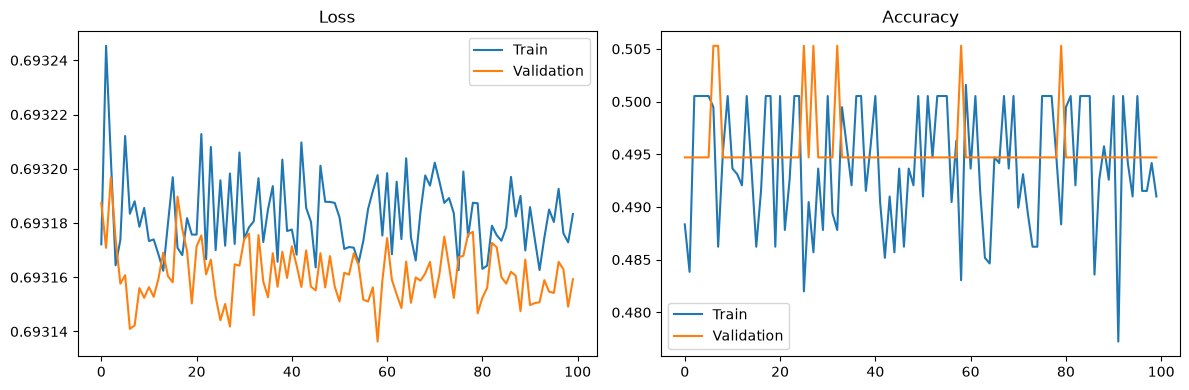

37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
              precision    recall  f1-score   support

      BAISSE       0.52      1.00      0.68       615
      HAUSSE       0.00      0.00      0.00       566

    accuracy                           0.52      1181
   macro avg       0.26      0.50      0.34      1181
weighted avg       0.27      0.52      0.36      1181



C:\Users\moi\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\moi\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\moi\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, 

In [34]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Courbe 1 : Évolution de la perte (Loss) sur train et validation
axes[0].plot(history.history['loss'], label='Train')
axes[0].plot(history.history['val_loss'], label='Validation')
axes[0].set_title('Loss')
axes[0].legend()

# Courbe 2 : Évolution de la précision (Accuracy) sur train et validation
axes[1].plot(history.history['accuracy'],     label='Train')
axes[1].plot(history.history['val_accuracy'], label='Validation')
axes[1].set_title('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()

y_proba = model.predict(X_test).flatten()

# Si probabilité >= 0.5 alors 1 (HAUSSE), sinon 0 (BAISSE)
y_pred  = (y_proba >= 0.5).astype(int)
print(classification_report(y_test, y_pred, target_names=['BAISSE','HAUSSE']))